<center><h1>xie_yiling_HW7</h1></center>

Name: yiling xie
<br>
Github Username: yilingx-333
<br>
USC ID: 3749312095

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [18]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, hamming_loss, silhouette_score
from sklearn.cluster import KMeans

from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import calinski_harabasz_score

### (a) Download the Anuran Calls (MFCCs) Data Set

In [19]:
data = pd.read_csv("../data/Frogs_MFCCs.csv")

X = data.iloc[:, :22]
y = data[["Family", "Genus", "Species"]]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42
)

print("Data shape:", data.shape)
print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Data shape: (7195, 26)
Training set: (5036, 22) (5036, 3)
Test set: (2159, 22) (2159, 3)


### (b) Train a classifier for each label

#### (i) Research

**Exact Match:** The percentage of instances for which all three predicted labels are correct. It is a strict metric because one incorrect label makes the entire prediction incorrect.

**Hamming Loss:** The fraction of individual labels that are predicted incorrectly.

**Hamming Score:** The fraction of individual labels that are predicted correctly. Therefore, Hamming Score = 1 - Hamming Loss.

#### (ii) Train a SVM for each of the labels

In [20]:
labels = ["Family", "Genus", "Species"]
param_grid = {
    "estimator__C": [0.01, 0.1, 1, 10, 100],
    "estimator__gamma": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
rbf_predictions = pd.DataFrame(index=y_test.index)

for label in labels:
    grid = GridSearchCV(
        OneVsRestClassifier(SVC(kernel="rbf")),
        param_grid,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )
    grid.fit(X_train, y_train[label])
    rbf_predictions[label] = grid.predict(X_test)
    print(label, grid.best_params_, round(grid.best_score_, 4))

exact_match = np.mean(
    np.all(y_test.values == rbf_predictions.values, axis=1)
)
rbf_hamming_loss = np.mean(
    y_test.values != rbf_predictions.values
)
rbf_hamming_score = 1 - rbf_hamming_loss

print("\nExact Match:", round(exact_match, 4))
print("Hamming Loss:", round(rbf_hamming_loss, 4))
print("Hamming Score:", round(rbf_hamming_score, 4))

Family {'estimator__C': 100, 'estimator__gamma': 1} 0.9915
Genus {'estimator__C': 10, 'estimator__gamma': 1} 0.9911
Species {'estimator__C': 10, 'estimator__gamma': 1} 0.9901

Exact Match: 0.9875
Hamming Loss: 0.0077
Hamming Score: 0.9923


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [21]:
c_grid = {"svc__C": [0.001, 0.01, 0.1, 1, 10, 100]}
l1_predictions = pd.DataFrame(index=y_test.index)

for label in labels:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", LinearSVC(penalty="l1", dual=False, max_iter=10000))
    ])
    
    grid = GridSearchCV(
        model, c_grid, cv=cv, scoring="accuracy", n_jobs=-1
    )
    grid.fit(X_train, y_train[label])
    l1_predictions[label] = grid.predict(X_test)
    print(label, grid.best_params_, round(grid.best_score_, 4))

l1_exact_match = np.mean(
    np.all(y_test.values == l1_predictions.values, axis=1)
)
l1_hamming_loss = np.mean(
    y_test.values != l1_predictions.values
)
l1_hamming_score = 1 - l1_hamming_loss

print("\nExact Match:", round(l1_exact_match, 4))
print("Hamming Loss:", round(l1_hamming_loss, 4))
print("Hamming Score:", round(l1_hamming_score, 4))

Family {'svc__C': 10} 0.9412
Genus {'svc__C': 100} 0.9516
Species {'svc__C': 10} 0.9607

Exact Match: 0.9125
Hamming Loss: 0.057
Hamming Score: 0.943


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [22]:
balanced_predictions = pd.DataFrame(index=y_test.index)

for label in labels:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", LinearSVC(
            penalty="l1",
            dual=False,
            class_weight="balanced",
            max_iter=10000
        ))
    ])
    
    grid = GridSearchCV(
        model, c_grid, cv=cv, scoring="accuracy", n_jobs=-1
    )
    grid.fit(X_train, y_train[label])
    balanced_predictions[label] = grid.predict(X_test)
    print(label, grid.best_params_, round(grid.best_score_, 4))

balanced_exact = np.mean(
    np.all(y_test.values == balanced_predictions.values, axis=1)
)
balanced_loss = np.mean(
    y_test.values != balanced_predictions.values
)
balanced_score = 1 - balanced_loss

print("\nExact Match:", round(balanced_exact, 4))
print("Hamming Loss:", round(balanced_loss, 4))
print("Hamming Score:", round(balanced_score, 4))

Family {'svc__C': 100} 0.9345
Genus {'svc__C': 10} 0.943
Species {'svc__C': 100} 0.9601

Exact Match: 0.9069
Hamming Loss: 0.0593
Hamming Score: 0.9407


**Conclusion:** The RBF SVM achieved the best performance, with an exact match of 0.9875 and a Hamming loss of 0.0077. The L1-penalized linear SVM performed worse. Class weighting did not improve the overall metrics, although it may help the minority classes by assigning them larger weights.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [23]:
X_all = data.iloc[:, :22]
cluster_runs = []
best_ks = []

for seed in range(50):
    best_score = -np.inf
    best_k = None
    best_clusters = None

    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            n_init=1,
            random_state=seed
        )
        clusters = model.fit_predict(X_all)
        score = calinski_harabasz_score(X_all, clusters)

        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters

    best_ks.append(best_k)
    cluster_runs.append(best_clusters)

print("Completed simulations:", len(cluster_runs))
print("Selected k values:")
print(pd.Series(best_ks).value_counts().sort_index())

Completed simulations: 50
Selected k values:
2    50
Name: count, dtype: int64


The Calinski-Harabasz score is undefined for k = 1, so k = 2, ..., 50 were evaluated. The criterion selected k = 2 in all 50 simulations, indicating that the strongest separation under this criterion was a two-cluster structure.

### (b) Determine which family is the majority

In [24]:
true_labels = data[labels]
cluster_predictions = []
majority_tables = []

for clusters in cluster_runs:
    predicted = pd.DataFrame(index=true_labels.index, columns=labels)
    rows = []

    for cluster in np.unique(clusters):
        mask = clusters == cluster
        majority = {}

        for label in labels:
            majority[label] = true_labels.loc[mask, label].mode()[0]
            predicted.loc[mask, label] = majority[label]

        rows.append({"Cluster": cluster, **majority})

    cluster_predictions.append(predicted)
    majority_tables.append(pd.DataFrame(rows))

print("Majority labels from the first simulation:")
display(majority_tables[0])

Majority labels from the first simulation:


,Cluster,Family,Genus,Species
0,0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,Hylidae,Hypsiboas,HypsiboasCordobae


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [25]:
simulation_results = []

for predicted in cluster_predictions:
    mismatches = true_labels.values != predicted.values

    distance = mismatches.sum(axis=1).mean()
    loss = mismatches.mean()
    score = 1 - loss

    simulation_results.append([distance, score, loss])

simulation_results = pd.DataFrame(
    simulation_results,
    columns=["Hamming Distance", "Hamming Score", "Hamming Loss"]
)

summary = pd.DataFrame({
    "Mean": simulation_results.mean(),
    "Standard Deviation": simulation_results.std()
})

summary.round(4)

,Mean,Standard Deviation
Hamming Distance,0.8956,0.0
Hamming Score,0.7015,0.0
Hamming Loss,0.2985,0.0


## 3. ISLR 12.6.2

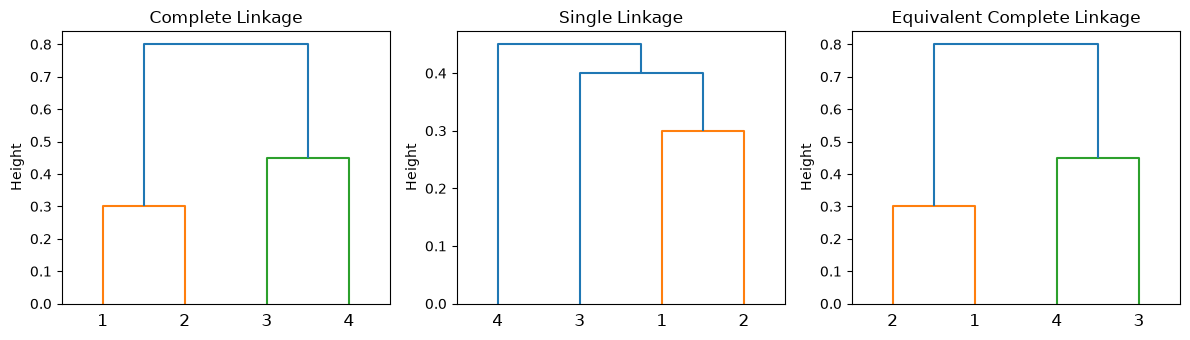

In [26]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

D = np.array([
    [0,   0.3, 0.4, 0.7],
    [0.3, 0,   0.5, 0.8],
    [0.4, 0.5, 0,   0.45],
    [0.7, 0.8, 0.45, 0]
])

distances = squareform(D)
complete = linkage(distances, method="complete")
single = linkage(distances, method="single")

equivalent = complete.copy()
equivalent[0, [0, 1]] = equivalent[0, [1, 0]]
equivalent[1, [0, 1]] = equivalent[1, [1, 0]]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

dendrogram(complete, labels=["1", "2", "3", "4"], ax=axes[0])
axes[0].set_title("Complete Linkage")

dendrogram(single, labels=["1", "2", "3", "4"], ax=axes[1])
axes[1].set_title("Single Linkage")

dendrogram(equivalent, labels=["1", "2", "3", "4"], ax=axes[2])
axes[2].set_title("Equivalent Complete Linkage")

for ax in axes:
    ax.set_ylabel("Height")

plt.tight_layout()
plt.show()

**(a) Complete linkage:** Observations 1 and 2 merge at 0.30, observations 3 and 4 merge at 0.45, and the two clusters merge at 0.80.

**(b) Single linkage:** Observations 1 and 2 merge at 0.30, observation 3 joins them at 0.40, and observation 4 joins at 0.45.

**(c)** Cutting the complete-linkage dendrogram into two clusters gives {1, 2} and {3, 4}.

**(d)** Cutting the single-linkage dendrogram into two clusters gives {1, 2, 3} and {4}.

**(e)** An equivalent complete-linkage dendrogram can use the leaf order 2, 1, 4, 3. Swapping branches does not change the fusion heights or cluster structure.